In [1]:
import numpy as np
from pyscf import gto, sftda
from pyscf.sftda.uhf_sf import get_ab_sf
from pyscf.grad import tduks_sf
import sys
sys.path.append('/home/peter/Research/ZeroExcitationEnergy/code/src')
from tools import extract_state

In [2]:
basis = 'cc-pvtz'
fun = 'B3LYP'

In [3]:
def tdgrad(mol):
    print(mol.tostring())

    mf = mol.UKS(xc=fun)
    mf.kernel()
    gse = mf.e_tot

    a, b = get_ab_sf(mf, collinear_samples=50)
    A_baba, A_abab = a
    B_baab, B_abba = b

    n_occ_a, n_virt_b = A_abab.shape[0], A_abab.shape[1]
    n_occ_b, n_virt_a = B_abba.shape[2], B_abba.shape[3]

    A_abab_2d = A_abab.reshape((n_occ_a*n_virt_b,n_occ_a*n_virt_b), order='C')
    B_abba_2d = B_abba.reshape((n_occ_a*n_virt_b,n_occ_b*n_virt_a), order='C')
    B_baab_2d = B_baab.reshape((n_occ_b*n_virt_a,n_occ_a*n_virt_b), order='C')
    A_baba_2d = A_baba.reshape((n_occ_b*n_virt_a,n_occ_b*n_virt_a), order='C')

    Casida_matrix = np.block([[ A_abab_2d, B_abba_2d],
                            [-B_baab_2d,-A_baba_2d]])

    eigenvals, eigenvecs = np.linalg.eig(Casida_matrix)

    idxt = eigenvals.real.argsort()
    eigenvals = eigenvals[idxt]
    eigenvecs = eigenvecs[:, idxt]

    norms = np.linalg.norm(eigenvecs[:n_occ_a * n_virt_b], axis=0)**2
    norms -= np.linalg.norm(eigenvecs[n_occ_a * n_virt_b:], axis=0)**2

    sfd_eigenvals = eigenvals[norms>0]
    sfd_eigenvecs = eigenvecs[:, norms>0].transpose(1,0)

    def norm_xy(z):
        x = z[:n_occ_a*n_virt_b].reshape(n_occ_a,n_virt_b)
        y = z[n_occ_a*n_virt_b:].reshape(n_occ_b,n_virt_a)
        norm = np.linalg.norm(x)**2 - np.linalg.norm(y)**2
        norm = np.sqrt(1./norm)
        return ((0,x*norm), (y*norm,0))

    mftd1 = sftda.TDA_SF(mf)
    mftd1.nstates = len(sfd_eigenvals)
    mftd1.extype = 1
    mftd1.collinear_samples = 50
    mftd1.e = sfd_eigenvals
    mftd1.xy = [norm_xy(z) for z in sfd_eigenvecs]

    S = extract_state(mf, mftd1)[0]
    T = extract_state(mf, mftd1, Smin=1.9, Smax=2.7)[0]

    e1 = mftd1.e[S] + gse
    e2 = mftd1.e[T] + gse

    mftdg1 = mftd1.Gradients()
    g1 = mftdg1.kernel(state=S+1)
    g2 = mftdg1.kernel(state=T+1)

    if e1 > e2:
        e1, e2 = e2, e1
        g1, g2 = g2, g1

    return e1, e2, g1, g2

In [4]:
atom = '''
O      0.63265879   -0.03758723    0.00000000
N     -0.53048232    0.10408252    0.00000000
H     -1.34789414   -0.42787980    0.00000000
'''
mol = gto.M(atom=atom, charge=0, spin=2, basis=basis)

In [5]:
R_list = []
f_list = []
u_list = []
f_R_list = []
e1_list = []
e2_list = []
sigma = 3.5
alpha = 0.02
tol_step = 1e-6
tol_grad = 0.005

def Fmidium(R):
    coords = R.reshape((mol.natm, 3))
    atom_new = [[mol.atom_symbol(i), coords[i]] for i in range(mol.natm)]
    mol_new = gto.M(atom=atom_new, charge=0, spin=2, basis=basis, unit='Bohr')
    e1, e2, g1, g2 = tdgrad(mol_new)
    g = (e1 - e2)**2 / (e2 - e1 + alpha)
    f = 0.5 * (e1 + e2) + sigma * g

    g1 = g1.flatten()
    g2 = g2.flatten()
    f_R = 0.5 * (g1 + g2)
    u = ((e1 - e2)**2 + 2 * alpha * (e2 - e1)) / (e2 - e1 + alpha)**2
    u *= (g2 - g1)
    f_R += sigma * u
    f_R_list.append(f_R)
    f_list.append(f)
    u_list.append(u / np.linalg.norm(u))
    R_list.append(R)
    e1_list.append(e1)
    e2_list.append(e2)
    return f, f_R, u

def F(R):
    f, f_R, u = Fmidium(R)
    return f, f_R

def callback(R):
    f0 = f_list[-2]
    f = f_list[-1]
    f_R = f_R_list[-1]
    u = u_list[-1]
    tol1 = np.abs(f0 - f) < tol_step
    tol2 = (f_R @ u / sigma) < tol_grad
    tol3 = np.linalg.norm(f_R - f_R @ u * u) < tol_grad
    print(f'Delta F = {np.abs(f0 - f):.2e},  Delta E = {np.abs(e1_list[-1] - e2_list[-1]):.2e}.')
    np.save('R', R)
    if tol1 and tol2 and tol3:
        raise StopIteration(f"Converged at given sigma={sigma:.2f}.")


# sigma = 3.5
# R0 = mol.atom_coords().flatten()
# from scipy.optimize import minimize
# result = minimize(fun=F, x0=R0, method='BFGS', jac=True, tol=1e-6, callback=callback)

In [7]:
R0 = np.load('R.npy')
sigma = 8.0
minimize(fun=F, x0=R0, method='BFGS', jac=True, tol=1e-6, callback=callback)

O           0.65311       -0.06617        0.00000
N          -0.54959        0.16413       -0.00000
H          -1.34928       -0.45941        0.00000
converged SCF energy = -130.504513916935  <S^2> = 2.0076118  2S+1 = 3.0050702
50
0-th state with excitation energy = -0.0864, S^2 = 0.0086 Norms: 0.945@(9, 1), 0.049@(8, 2)
2-th state with excitation energy = 0.7933, S^2 = 0.0100 Norms: 0.497@(8, 1), 0.497@(9, 2)
3-th state with excitation energy = 3.0558, S^2 = 0.0083 Norms: 0.948@(8, 2), 0.050@(9, 1)
1-th state with excitation energy = 0.0000, S^2 = 2.0407 Norms: 0.496@(9, 2), 0.495@(8, 1)
14-th state with excitation energy = 12.6821, S^2 = 1.9902 Norms: 0.972@(7, 3), 0.007@(7, 4)
15-th state with excitation energy = 12.8745, S^2 = 1.9767 Norms: 0.960@(6, 3), 0.011@(9, 5)
50
--------- TDA_SF gradients for state 1 ----------
         x                y                z
0 O     0.0522747985     0.0306344613    -0.0000000000
1 N    -0.0431784914    -0.0846187352     0.0000000000
2 H    -0.

StopIteration: Converged at given sigma=8.00.

In [8]:
R0 = np.load('R.npy')
sigma = 15.0
minimize(fun=F, x0=R0, method='BFGS', jac=True, tol=1e-6, callback=callback)

O           0.65764       -0.06099        0.00000
N          -0.54752        0.15474       -0.00000
H          -1.35587       -0.45524        0.00000
converged SCF energy = -130.50373062185  <S^2> = 2.0076334  2S+1 = 3.0050846
50
0-th state with excitation energy = -0.0348, S^2 = 0.0085 Norms: 0.942@(9, 1), 0.053@(8, 2)
2-th state with excitation energy = 0.7950, S^2 = 0.0099 Norms: 0.497@(8, 1), 0.497@(9, 2)
3-th state with excitation energy = 3.0015, S^2 = 0.0081 Norms: 0.944@(8, 2), 0.054@(9, 1)
1-th state with excitation energy = 0.0000, S^2 = 2.0408 Norms: 0.496@(9, 2), 0.495@(8, 1)
14-th state with excitation energy = 12.6615, S^2 = 1.9907 Norms: 0.970@(7, 3), 0.008@(7, 4)
15-th state with excitation energy = 12.8502, S^2 = 1.9780 Norms: 0.960@(6, 3), 0.009@(9, 5)
50
--------- TDA_SF gradients for state 1 ----------
         x                y                z
0 O     0.0514172991     0.0331182474    -0.0000000000
1 N    -0.0422830654    -0.0892824106     0.0000000000
2 H    -0.0

StopIteration: Converged at given sigma=15.00.

In [6]:
from scipy.optimize import minimize
R0 = np.load('R.npy')
sigma = 25.0
minimize(fun=F, x0=R0, method='BFGS', jac=True, tol=1e-6, callback=callback)

O           0.65903592       -0.05932680        0.00000000
N          -0.54687509        0.15169275       -0.00000000
H          -1.35791493       -0.45388291        0.00000000


/home/peter/anaconda3/envs/sftddavid/lib/python3.10/site-packages/pyscf/dft/libxc.py:512: UserWarning: Since PySCF-2.3, B3LYP (and B3P86) are changed to the VWN-RPA variant, corresponding to the original definition by Stephens et al. (issue 1480) and the same as the B3LYP functional in Gaussian. To restore the VWN5 definition, you can put the setting "B3LYP_WITH_VWN5 = True" in pyscf_conf.py
  warnings.warn('Since PySCF-2.3, B3LYP (and B3P86) are changed to the VWN-RPA variant, '


converged SCF energy = -130.50345996421  <S^2> = 2.0076408  2S+1 = 3.0050896
50
0-th state with excitation energy = -0.0180, S^2 = 0.0084 Norms: 0.940@(9, 1), 0.054@(8, 2)
2-th state with excitation energy = 0.7955, S^2 = 0.0099 Norms: 0.497@(8, 1), 0.497@(9, 2)
3-th state with excitation energy = 2.9839, S^2 = 0.0081 Norms: 0.943@(8, 2), 0.055@(9, 1)
1-th state with excitation energy = 0.0000, S^2 = 2.0408 Norms: 0.496@(9, 2), 0.495@(8, 1)
14-th state with excitation energy = 12.6547, S^2 = 1.9908 Norms: 0.970@(7, 3), 0.009@(7, 4)
15-th state with excitation energy = 12.8423, S^2 = 1.9784 Norms: 0.960@(6, 3), 0.009@(9, 5)
50
--------- TDA_SF gradients for state 1 ----------
         x                y                z
0 O     0.0510863597     0.0338825252     0.0000000000
1 N    -0.0419952392    -0.0907287639     0.0000000000
2 H    -0.0090916766     0.0568595515    -0.0000000000
----------------------------------------------
50
--------- TDA_SF gradients for state 2 ----------
      

  message: `callback` raised `StopIteration`.
  success: False
   status: 99
      fun: -130.5033469835879
        x: [ 1.246e+00 -1.108e-01  1.216e-14 -1.033e+00  2.841e-01
            -2.440e-14 -2.568e+00 -8.565e-01  2.183e-15]
      nit: 3
      jac: [-4.879e-05  5.336e-05 -1.616e-15 -8.547e-05 -1.844e-04
            -9.187e-15  1.332e-04  1.443e-04  1.029e-14]
 hess_inv: [[ 7.762e-01 -4.370e-02 ... -1.375e-01 -8.166e-13]
            [-4.370e-02  9.364e-01 ... -1.228e-01  4.358e-13]
            ...
            [-1.375e-01 -1.228e-01 ...  8.107e-01  3.053e-13]
            [-8.166e-13  4.358e-13 ...  3.053e-13  1.000e+00]]
     nfev: 5
     njev: 5

In [9]:
R = np.load('R.npy')
coords = R.reshape((mol.natm, 3))
atom_new = [[mol.atom_symbol(i), coords[i]] for i in range(mol.natm)]
mol_new = gto.M(atom=atom_new, charge=0, spin=2, basis=basis, unit='Bohr')
e1, e2, g1, g2 = tdgrad(mol_new)

O           0.65904       -0.05933        0.00000
N          -0.54688        0.15169       -0.00000
H          -1.35791       -0.45388        0.00000
converged SCF energy = -130.503459953995  <S^2> = 2.0076408  2S+1 = 3.0050896
50
0-th state with excitation energy = -0.0180, S^2 = 0.0084 Norms: 0.940@(9, 1), 0.054@(8, 2)
2-th state with excitation energy = 0.7955, S^2 = 0.0099 Norms: 0.497@(8, 1), 0.497@(9, 2)
3-th state with excitation energy = 2.9839, S^2 = 0.0081 Norms: 0.943@(8, 2), 0.055@(9, 1)
1-th state with excitation energy = 0.0000, S^2 = 2.0408 Norms: 0.496@(9, 2), 0.495@(8, 1)
14-th state with excitation energy = 12.6547, S^2 = 1.9908 Norms: 0.970@(7, 3), 0.009@(7, 4)
15-th state with excitation energy = 12.8423, S^2 = 1.9784 Norms: 0.960@(6, 3), 0.009@(9, 5)
50
--------- TDA_SF gradients for state 1 ----------
         x                y                z
0 O     0.0510862617     0.0338825683    -0.0000000000
1 N    -0.0419957054    -0.0907291139     0.0000000000
2 H    -0.

In [10]:
g2 - g1

array([[-3.53500321e-02, -2.34486357e-02,  3.07218355e-16],
       [ 2.90377909e-02,  6.27989132e-02, -2.98186534e-15],
       [ 6.31219196e-03, -3.93496591e-02,  2.73649010e-15]])

In [12]:
print(mol_new.tostring())

O           0.65904       -0.05933        0.00000
N          -0.54688        0.15169       -0.00000
H          -1.35791       -0.45388        0.00000


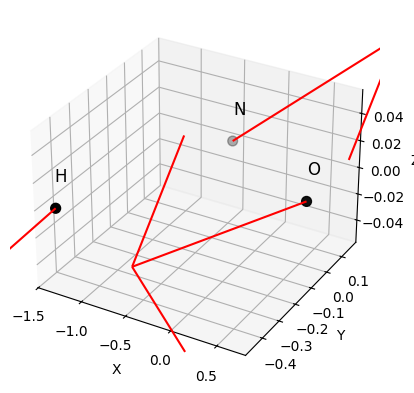

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 原子位置
R = np.array([
    [ 0.65904, -0.05933,  0.00000],    # O
    [-0.54688,  0.15169, -0.00000],    # N
    [-1.35791, -0.45388,  0.00000],    # H
])

# 矢量
V = np.array([
    [-3.53500321e-02, -2.34486357e-02,  3.07218355e-16],
    [ 2.90377909e-02,  6.27989132e-02, -2.98186534e-15],
    [ 6.31219196e-03, -3.93496591e-02,  2.73649010e-15]
])

labels = ['O', 'N', 'H']

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# 画原子散点
ax.scatter(R[:,0], R[:,1], R[:,2], c='k', s=50)
for i, label in enumerate(labels):
    ax.text(R[i,0], R[i,1], R[i,2]+0.02, label, fontsize=12)

# 画矢量（每个原子1个）
ax.quiver(R[:,0], R[:,1], R[:,2], V[:,0], V[:,1], V[:,2], color='r', length=1, normalize=True)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()


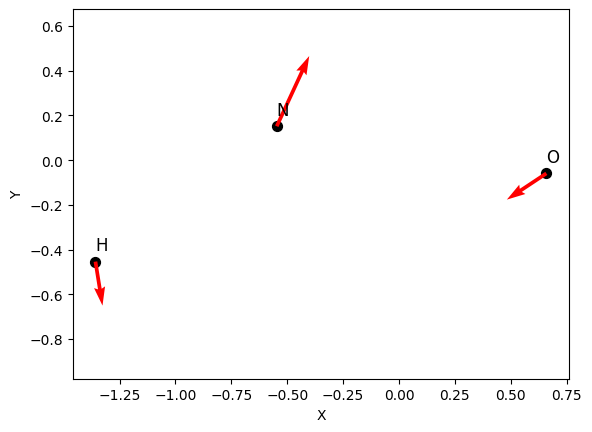

In [2]:
import numpy as np
import matplotlib.pyplot as plt

R = np.array([
    [ 0.65904, -0.05933],    # O
    [-0.54688,  0.15169],    # N
    [-1.35791, -0.45388],    # H
])

V = np.array([
    [-3.53500321e-02, -2.34486357e-02],
    [ 2.90377909e-02,  6.27989132e-02],
    [ 6.31219196e-03, -3.93496591e-02]
])
labels = ['O', 'N', 'H']

plt.figure()
plt.scatter(R[:,0], R[:,1], c='k', s=50)
for i, label in enumerate(labels):
    plt.text(R[i,0], R[i,1]+0.05, label, fontsize=12)

plt.quiver(R[:,0], R[:,1], V[:,0], V[:,1], color='r', angles='xy', scale_units='xy', scale=0.2) 
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal')
plt.show()
